**Value at Risk Forecasting and Backtesting using GARCH method**

**Final Capstone Project**

**IIT Ropar**

**Group Members - Georgy S Pulayath, Joshi Bhavin Rasikbhai, Prabhujeet Sahu, Shrenik Nandre**

**Guide: Prof. Punit Pasricha (IIT Ropar)**

## How to read this notebook

Method note: `GARCH.md`. Portfolio: **1,000 units** of the Nifty 50 (₹21,03,750 on 4 January 2005).

The comparison in the report uses the first 1,002 rows, 95% VaR, and two forecasts:

| Model | Violations on the illustrated test | AE ratio |
| --- | --- | --- |
| Delta-normal (one mean, one volatility) | 45 | 3.75 |
| Rolling GARCH(1,1), Student-t | 13 | about 1.0 |

Log returns are multiplied by 100 before estimation, so every VaR in this notebook is in percent. Compare it with the scaled returns.

`n_start = 753` is the length of each estimation window. The following ~250 days are the test. The Student-t degrees of freedom are fixed at 3.7545967917 inside the loop. The first rolling specification is GARCH(1,1) (`p=1, q=1`). The three later blocks set `q=0`, which is ARCH(1); the print statement still says GARCH.


In [86]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\GARCH


In [87]:
# Core stack: pandas/numpy, plots, ARIMA diagnostics, arch GARCH, and the
# normal, Student-t, binomial, and chi-square pieces used in VaR and backtests.
# yfinance is unused; prices come from the local workbook.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from arch import arch_model 
from tabulate import tabulate
from scipy.stats import norm, t, binom, chi2


In [88]:
# Columns used throughout: Dates, NIFTY Index.

nifty_df = pd.read_excel(NIFTY_PATH)  # data/Nifty50_data.xlsx


In [89]:
# 1,000 index units, held fixed. This is the ₹21,03,750 book on 4 January 2005
# cited in the report (1,000 times the opening index level).

shares_held = 1000 # Number of shares purchased
initial_investment = shares_held * nifty_df['NIFTY Index'] # Initial investment amount
# Calculate the portfolio value based on the number of shares held
nifty_df['Portfolio Value'] = shares_held * nifty_df['NIFTY Index']


In [90]:
# Tail check that the file loaded and the portfolio column exists.

nifty_df.tail()


,Dates,EIM IS Equity,AXSB IS Equity,BJFIN IS Equity,SBILIFE IS Equity,RELIANCE IS Equity,ITC IS Equity,MM IS Equity,SBIN IS Equity,HNDL IS Equity,...,DIVI IS Equity,UTCEM IS Equity,UPLL IS Equity,TECHM IS Equity,BJAUT IS Equity,BRIT IS Equity,GRASIM IS Equity,TATACONS IS Equity,NIFTY Index,Portfolio Value
4884,2023-09-25,3386.65,1018.95,1577.40,1294.15,2340.45,442.60,1589.45,594.05,469.35,...,3728.50,8206.20,616.95,1299.45,5005.45,4570.05,1939.85,900.60,19674.55,19674550.0
4885,2023-09-26,3472.15,1014.15,1567.70,1289.70,2342.50,442.45,1595.20,594.40,471.50,...,3753.80,8228.90,617.55,1282.30,5069.20,4600.15,1958.00,895.20,19664.70,19664700.0
4886,2023-09-27,3479.70,1025.20,1565.75,1301.00,2368.90,449.15,1589.20,589.75,474.95,...,3768.00,8262.70,615.10,1288.65,5032.95,4627.35,1931.10,888.85,19716.45,19716450.0
4887,2023-09-28,3440.25,1030.90,1539.70,1289.40,2334.10,440.75,1556.05,589.95,466.85,...,3665.00,8154.35,605.00,1229.50,5006.60,4524.55,1906.50,876.50,19523.55,19523550.0
4888,2023-09-29,3446.95,1036.70,1540.25,1305.40,2345.00,444.40,1554.25,598.55,492.65,...,3765.15,8254.85,616.25,1222.80,5063.70,4537.15,1942.40,876.90,19638.30,19638300.0


In [91]:
# Illustrated sample in the report: the first 1,002 rows.
# Log returns below will drop the first row, leaving about 1,001 returns.

nf_train = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[0:1002]
nf_train.head()


,Dates,NIFTY Index,Portfolio Value
0,2005-01-04,2103.75,2103750.0
1,2005-01-05,2032.20,2032200.0
2,2005-01-06,1998.35,1998350.0
3,2005-01-07,2015.50,2015500.0
4,2005-01-10,1982.00,1982000.0


In [92]:
# A short slice kept from an earlier experiment. The rolling test used later
# is log_returns[753:1002], not this 252:315 slice.

nf_test= nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[252:315]


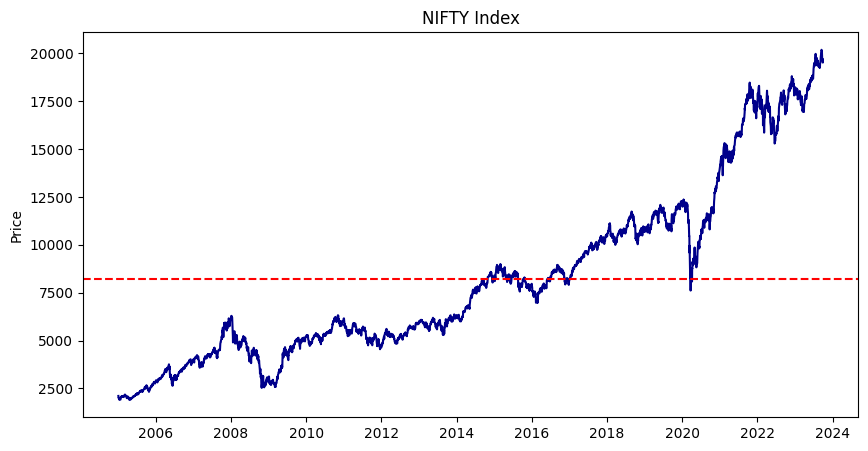

In [93]:
# Log return on the estimation sample, then the full-sample index level
# with its mean drawn as a reference line.

nf_train['Log Returns'] = np.log(nf_train['NIFTY Index'] / nf_train['NIFTY Index'].shift(1))
plt.figure(figsize=(10, 5))
sns.lineplot(x=nifty_df['Dates'], y=nifty_df['NIFTY Index'], color='darkblue')
plt.axhline(y=nifty_df['NIFTY Index'].mean(), color='red', linestyle='--')
plt.xlabel('')
plt.ylabel('Price')
plt.title('NIFTY Index')
plt.show()


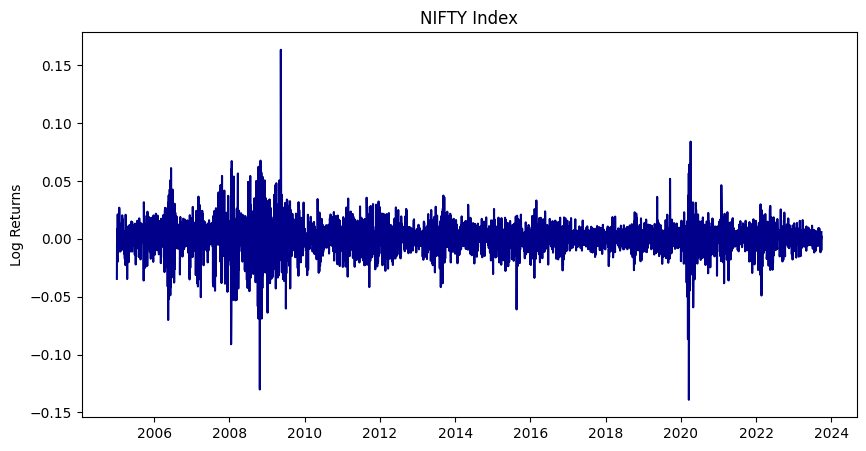

In [94]:
# Full-sample log returns. Clustering (calm spells, then turbulent spells)
# is the reason a single volatility is a weak VaR input.

log_returns= np.log(nifty_df['NIFTY Index'] / nifty_df['NIFTY Index'].shift(1))
log_returns.dropna(inplace=True)
plt.figure(figsize=(10, 5))
sns.lineplot(x=nifty_df['Dates'].shift(1), y=log_returns, color='darkblue')
plt.xlabel('')
plt.ylabel('Log Returns')
plt.title('NIFTY Index')
plt.show()


**Visualizing Log Returns**

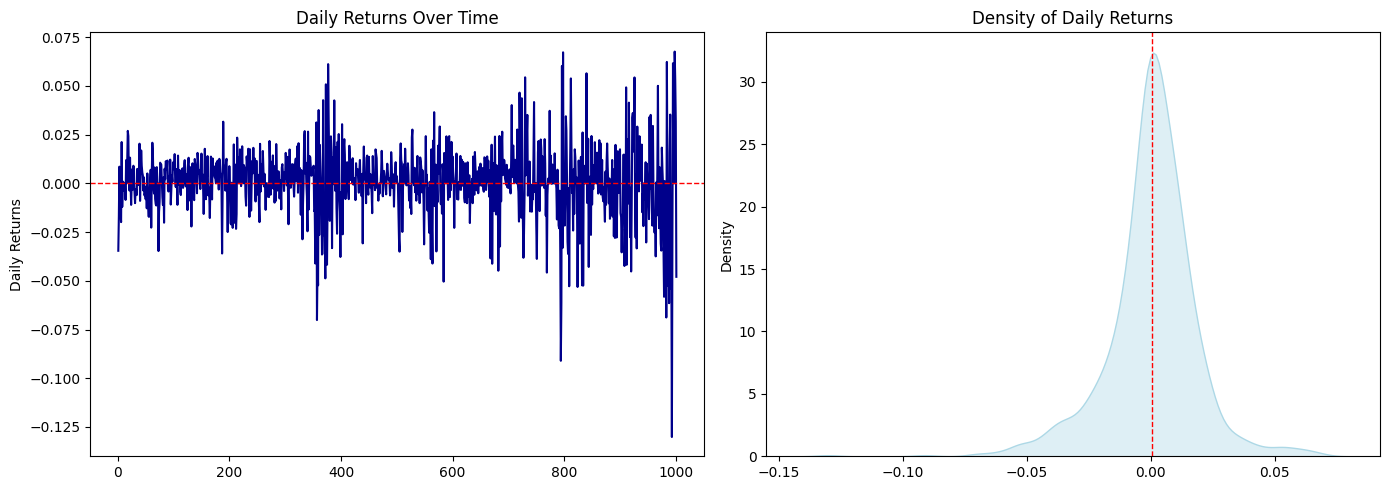

In [95]:
# Left: returns through time, the picture of volatility clustering.
# Right: density. The report reads this shape as leptokurtic (heavy tails),
# which motivates the Student-t quantile later.

def plot_returns(nf_train):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Line plot of daily returns
    sns.lineplot(x=range(len(nf_train['Log Returns'])), y=nf_train['Log Returns'], color='darkblue', ax=axes[0])
    axes[0].axhline(y=nf_train['Log Returns'].mean(), color='red', linestyle='--', linewidth=1)
    axes[0].set_xlabel('')
    axes[0].set_ylabel('Daily Returns')
    axes[0].set_title('Daily Returns Over Time')
    
    # Density plot of daily returns
    sns.kdeplot(nf_train['Log Returns'], fill=True, color='lightblue', alpha=0.4, ax=axes[1])
    axes[1].axvline(x=nf_train['Log Returns'].mean(), color='red', linestyle='--', linewidth=1)
    axes[1].set_xlabel('')
    axes[1].set_title('Density of Daily Returns')
    
    plt.tight_layout()
    plt.show()

plot_returns(nf_train)


In [96]:
# Scale to percent. The arch optimiser is more stable on this scale,
# and VaR must be compared with these scaled returns.

nf_train['Log Returns']*=100


In [97]:
# ADF unit-root test. A p-value below 0.05, as on this series, means the
# log-return series is treated as stationary and can be modelled directly.

# Perform ADF test
from statsmodels.tsa.stattools import adfuller
adf_result = adfuller(nf_train['Log Returns'].dropna())
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])


ADF Statistic: -6.518941905480205
p-value: 1.0539952273613569e-08


p-value of ADF test is <0.05 which implies that log returns does not have unit root. That means the time series is stationary.

In [98]:
# AR(2) mean equation, used only as a diagnostic. VaR itself comes from
# the variance models below, not from this ARIMA forecast.

model_arima = ARIMA(nf_train['Log Returns'].dropna(), order=(2, 0, 0))
model_arima_fit = model_arima.fit()
print(model_arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:            Log Returns   No. Observations:                 1001
Model:                 ARIMA(2, 0, 0)   Log Likelihood               -2011.629
Date:                Tue, 04 Mar 2025   AIC                           4031.258
Time:                        19:17:59   BIC                           4050.894
Sample:                             0   HQIC                          4038.721
                               - 1001                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0347      0.067      0.521      0.602      -0.096       0.165
ar.L1          0.0660      0.022      3.047      0.002       0.024       0.108
ar.L2          0.0034      0.019      0.181      0.8

C:\Users\BHAVIN JOSHI\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\BHAVIN JOSHI\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)
C:\Users\BHAVIN JOSHI\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: An unsupported index was pr

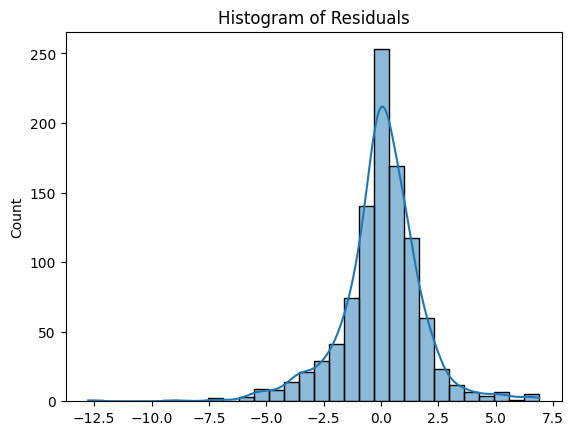

      lb_stat  lb_pvalue
14  29.904955   0.007865


In [99]:
# If the AR(2) mean is adequate, residual autocorrelation should be weak.
# The histogram shows the heavy tails that a normal residual would not have.
# Ljung-Box at 14 lags is the formal autocorrelation check.

# Residual Analysis
from statsmodels.stats.diagnostic import acorr_ljungbox
residuals = model_arima_fit.resid
sns.histplot(residuals, kde=True, bins=30)
plt.title("Histogram of Residuals")
plt.show()

# Ljung-Box Test
ljung_box_result = acorr_ljungbox(residuals, lags=[14], return_df=True)
print(ljung_box_result)


In [100]:
# One GARCH(1,1) on those residuals:
# sigma^2_t = omega + alpha_1 * eps^2_{t-1} + beta_1 * sigma^2_{t-1}.
# This fit introduces the variance equation. The rolling VaR loop refits it.

# Fit GARCH(1,1) model
garch_model = arch_model(residuals, vol='Garch', p=1, q=1)
garch_fit = garch_model.fit(disp='off')
print(garch_fit.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -1823.50
Distribution:                  Normal   AIC:                           3655.00
Method:            Maximum Likelihood   BIC:                           3674.64
                                        No. Observations:                 1001
Date:                Tue, Mar 04 2025   Df Residuals:                     1000
Time:                        19:17:59   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1175  4.278e-02      2.747  6.013e-03 [3.368e-0

**Delta Approach**

In [101]:
# A single normal left-tail number from the unconditional GARCH variance (omega).
# alpha = 0.05 is a 95% VaR. The printed label says 99%; the quantile used is 5%.

from scipy.stats import t
from scipy.stats import norm
import numpy as np


# Extract the relevant parameters
mu = garch_fit.params['mu']        # Mean (Assumed to be zero in many cases)
omega = garch_fit.params['omega']  # Conditional variance (Omega)
alpha_1 = garch_fit.params['alpha[1]']  # GARCH parameter
beta_1 = garch_fit.params['beta[1]']    # GARCH parameter

# Standard deviation (sqrt of omega)
sigma = np.sqrt(omega)

# Quantile for 99% confidence level (5th percentile)
alpha = 0.05
z_alpha = norm.ppf(alpha)  # Quantile for 5% tail in standard normal distribution

# Calculate the 5th percentile (VaR at 99% confidence level)
var_99 = mu + z_alpha * sigma

print(f"5th Percentile (VaR at 99% confidence level): {var_99}")


5th Percentile (VaR at 99% confidence level): -0.33696163899979514


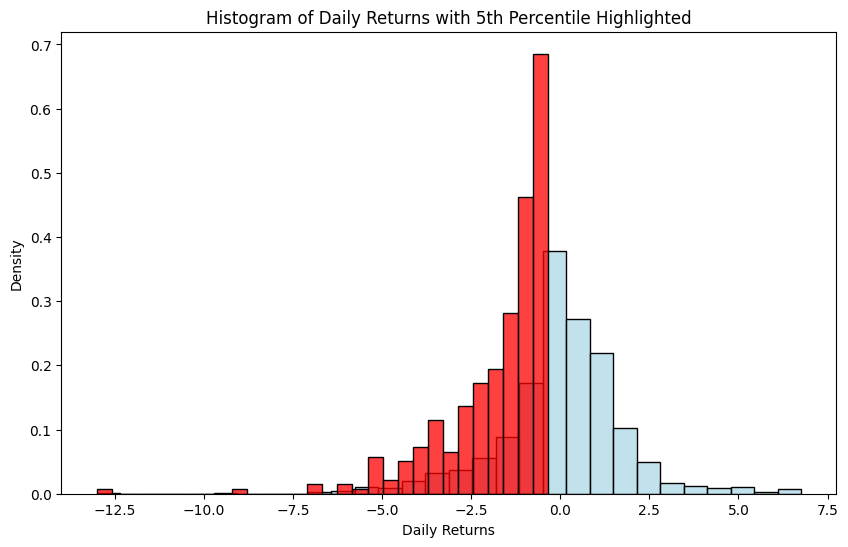

In [102]:
# Highlight the part of the estimation-sample density that sits below that threshold.

plt.figure(figsize=(10, 6))

# Plot the full histogram
sns.histplot(nf_train['Log Returns'], bins=30, color='lightblue', kde=False, stat='density')

# Plot the histogram for values below the 5th percentile (highlight VaR)
sns.histplot(nf_train['Log Returns'][nf_train['Log Returns'] < var_99], bins=30, color='red', kde=False, stat='density')

# Add labels
plt.xlabel('Daily Returns')
plt.title('Histogram of Daily Returns with 5th Percentile Highlighted')

# Show the plot
plt.show()


In [103]:
# Normal versus Student-t critical values at 5% and 1%.
# shape_param = 3.75 is a heavy-tailed t (the normal limit is large df).
# The rolling VaR uses the 5% t quantile, not the normal one.

from scipy.stats import t, norm
from arch import arch_model

# Fit t-distribution to the residuals
from scipy.stats import t
params = garch_fit.params
# Parameters for t-distribution (estimated manually from the GARCH model)
shape_param = 3.7545967917

# Quantile values for normal distribution
alpha_5 = 0.05
alpha_1 = 0.01
qnorm_5 = norm.ppf(alpha_5)
qnorm_1 = norm.ppf(alpha_1)

print(f"For α = 0.05, the quantile value of the normal distribution is: {qnorm_5}")
print(f"For α = 0.01, the quantile value of the normal distribution is: {qnorm_1}")

# Quantile values for t-distribution
qt_5 = t.ppf(alpha_5, df=shape_param)
qt_1 = t.ppf(alpha_1, df=shape_param)

print(f"For α = 0.05, the quantile value of the t-distribution is: {qt_5}")
print(f"For α = 0.01, the quantile value of the t-distribution is: {qt_1}")


For α = 0.05, the quantile value of the normal distribution is: -1.6448536269514729
For α = 0.01, the quantile value of the normal distribution is: -2.3263478740408408
For α = 0.05, the quantile value of the t-distribution is: -2.1725188343061292
For α = 0.01, the quantile value of the t-distribution is: -3.8859498919710074


**GARCH Method using Rolling Window Approach**

In [104]:
# Series that enters the rolling loop: scaled log returns, first row already dropped.

log_returns = nf_train['Log Returns'].dropna()
nf_train.head()


,Dates,NIFTY Index,Portfolio Value,Log Returns
0,2005-01-04,2103.75,2103750.0,NaN
1,2005-01-05,2032.20,2032200.0,-3.460252
2,2005-01-06,1998.35,1998350.0,-1.679711
3,2005-01-07,2015.50,2015500.0,0.854546
4,2005-01-10,1982.00,1982000.0,-1.676087


In [105]:
# Inspect the series length before the 753 / remaining-days split.

print("Log Returns:")
print(log_returns)


Log Returns:
1      -3.460252
2      -1.679711
3       0.854546
4      -1.676087
5      -1.522633
          ...   
997     0.000000
998     6.757427
999     5.339031
1000    3.176820
1001   -4.796383
Name: Log Returns, Length: 1001, dtype: float64


In [106]:
# Rolling 95% GARCH-t VaR.
# For each day i, refit GARCH(1,1) with Student-t innovations on the
# previous 753 scaled returns. VaR_i = mu + sigma_i * t.ppf(0.05, df).
# Only the last conditional volatility of each fit is kept.
# The report scores this forecast at about 13 violations (AE near 1).

# Rolling VaR calculation
n_start = 753  # Initial training size
alpha_5 = 0.05  # Confidence level for VaR
shape_param = 3.7545967917  # Degrees of freedom for t-distribution
rolling_var_95_td = []
for i in range(n_start, len(log_returns)):
    rolling_data = log_returns.iloc[i - n_start:i]  # Use `.iloc` for slicing
    
    # Fit GARCH(1,1) with t-distribution
    garch_model = arch_model(rolling_data, vol='Garch', p=1, q=1, dist='t')
    garch_fit = garch_model.fit(disp='off')
    
    # Extract parameters
    sigma = garch_fit.conditional_volatility.iloc[-1]  # Use `.iloc[-1]` for the last value
    mu = garch_fit.params['mu'] if 'mu' in garch_fit.params else 0
    
    # Compute 95% VaR
    var_95 = mu + sigma * t.ppf(alpha_5, df=shape_param)
    rolling_var_95_td.append(var_95)
    


In [107]:
# A violation is a test return more negative than that day's VaR.
# test_log_returns and VaR95_td must stay aligned: both start at index 753.

VaR95_td = np.array(rolling_var_95_td)
test_log_returns = log_returns[753:1002]
exceptions_garch = np.sum(test_log_returns < VaR95_td)


In [108]:
# Length check. The loop runs from index 753 to the end of log_returns,
# so this count is the number of scored days (about 250 in the report).

print(len(rolling_var_95_td))


248


In [109]:
# Attach dates for the plot. iloc[n_start + 1:] lines the date index up
# with a return series that has already lost its first row.

# Convert to DataFrame for analysis
rolling_var_df = pd.DataFrame({
    'Date': nf_train['Dates'].iloc[n_start+1:].values,
    'VaR 95% t-dist': rolling_var_95_td
}).set_index('Date')


            VaR 95% t-dist
Date                      
2007-11-26       -4.211924
2007-11-27       -4.012603
2007-11-28       -3.975951
2007-11-29       -3.704500
2007-11-30       -3.634586


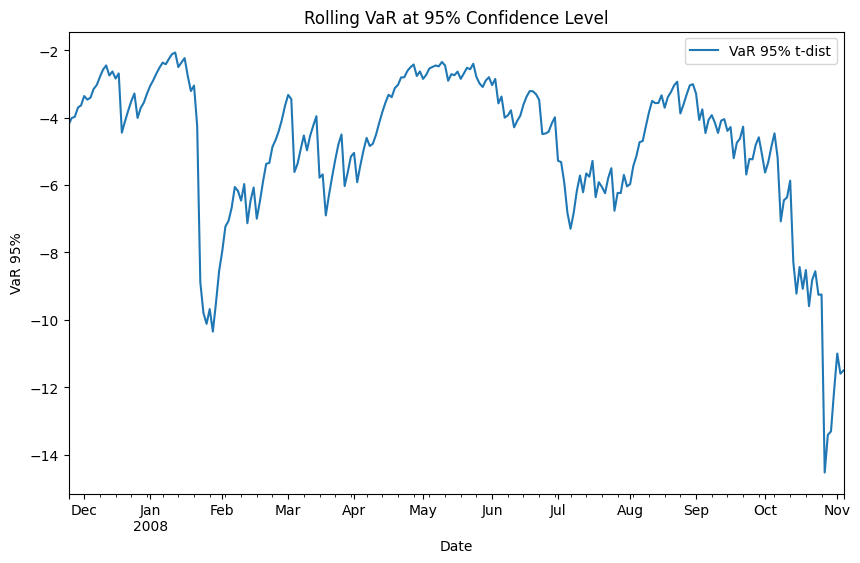

In [110]:
# The VaR path should widen in turbulent stretches and narrow in calm ones.
# That movement is the practical difference from the flat delta-normal line.


print(rolling_var_df.head())
rolling_var_df.plot(title="Rolling VaR at 95% Confidence Level", figsize=(10, 6))
plt.ylabel('VaR 95%')
plt.xlabel('Date')
plt.show()


In [111]:
# Binomial benchmark: how many exceptions are plausible in 500 trials
# when each day breaches with probability 0.05. This is a reference curve
# for exception counts, not the test-window length (the test window is ~250).

from scipy.stats import binom, norm
# We have log returns as Daily returns
VaR95_td = np.array(rolling_var_95_td)  # 95% VaR from the GARCH model
# Initialize probabilities array
p = np.zeros(50)
p[0] = binom.cdf(0, n=500, p=0.05)  # Cumulative probability for 0 exceptions
for i in range(1, 50):
    p[i] = binom.cdf(i, n=500, p=0.05) - binom.cdf(i - 1, n=500, p=0.05)  # Binomial probability for each exception count


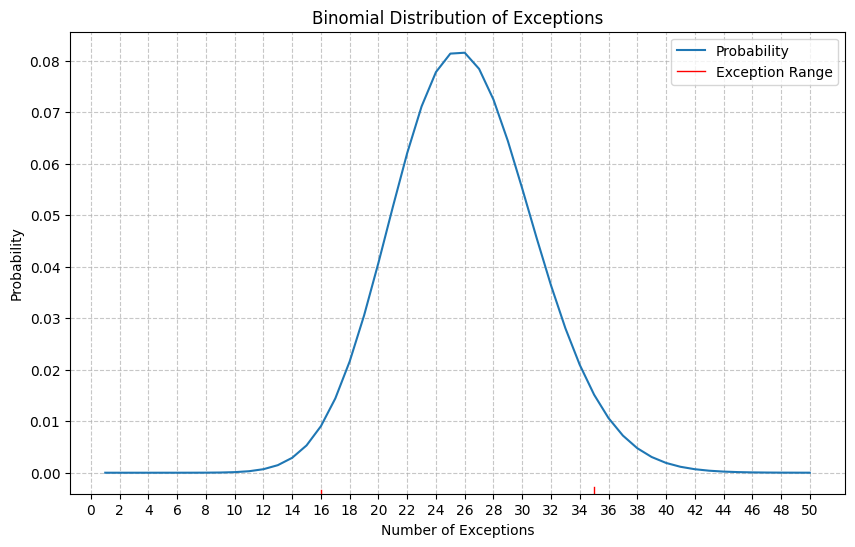

In [112]:
# The vertical lines at 16 and 35 mark a conventional acceptance band
# on that binomial curve.

# Plot the binomial distribution
plt.figure(figsize=(10, 6))
plt.plot(range(1, 51), p, label='Probability')
plt.xticks(ticks=np.arange(0, 51, 2))
plt.axvline(x=16, ymin=0, ymax=p[15], color='red', linewidth=1, label='Exception Range')
plt.axvline(x=35, ymin=0, ymax=p[34], color='red', linewidth=1)
plt.ylabel('Probability')
plt.xlabel('Number of Exceptions')
plt.title('Binomial Distribution of Exceptions')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


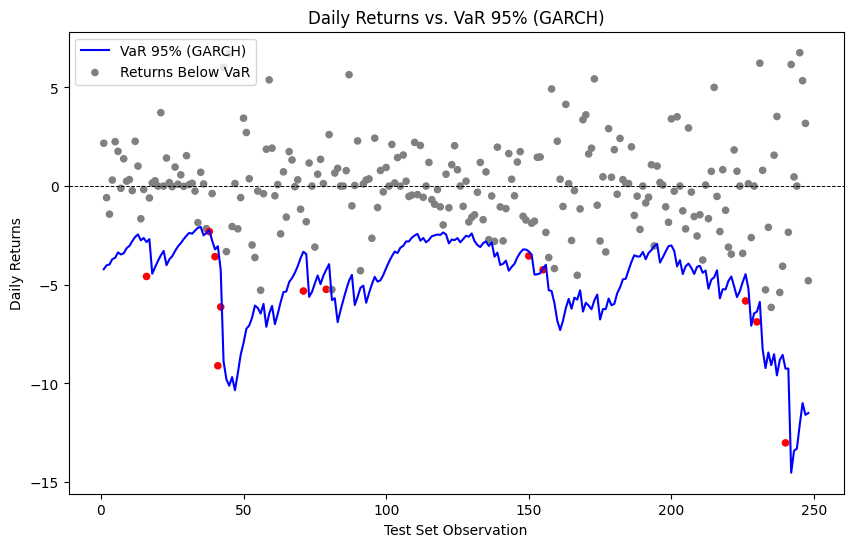

In [113]:
# Test returns against the moving 95% GARCH VaR.
# Red points are violations (return below VaR). Gray points are inside the threshold.
# range(1, 249) assumes 248 scored points; if the lengths differ, trim before plotting.

# Plot daily returns vs. VaR95_td
test_log_returns = log_returns[753:1002]  # Test set (adjust based on your rolling window setup)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 249), VaR95_td, label='VaR 95% (GARCH)', color='blue')
plt.scatter(range(1, 249), test_log_returns, c=['red' if x < VaR95_td[i] else 'gray' for i, x in enumerate(test_log_returns)], s=20, label='Daily Returns')
plt.axhline(y=0, color='black', linestyle='--', linewidth=0.7)
plt.ylabel('Daily Returns')
plt.xlabel('Test Set Observation')
plt.title('Daily Returns vs. VaR 95% (GARCH)')
plt.legend(['VaR 95% (GARCH)', 'Returns Below VaR'], loc='upper left')
plt.show()


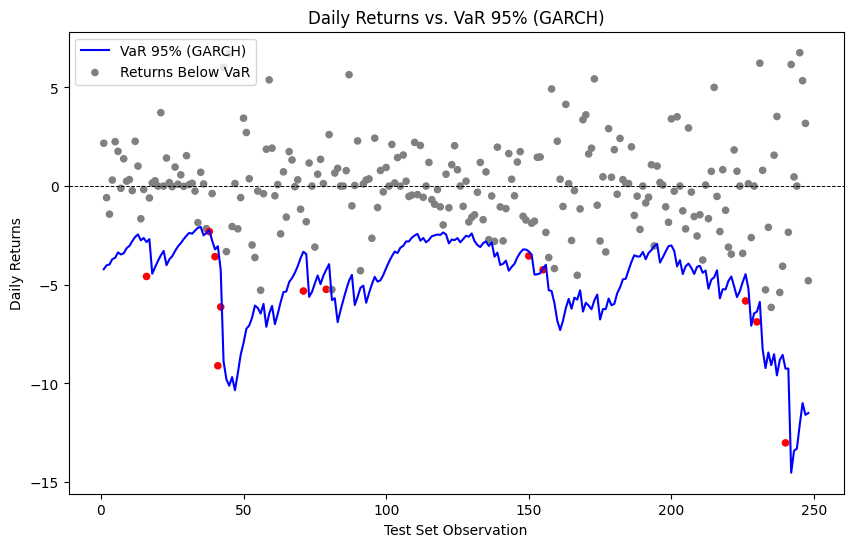

In [114]:
# Same breach chart, repeated so the figure can sit next to the coverage tests.

# Plot daily returns vs. VaR95_td
plt.figure(figsize=(10, 6))
plt.plot(range(1, 249), VaR95_td, label='VaR 95% (GARCH)', color='blue')
plt.scatter(range(1, 249), test_log_returns, c=['red' if x < VaR95_td[i] else 'gray' for i, x in enumerate(test_log_returns)], s=20, label='Daily Returns')
plt.axhline(y=0, color='black', linestyle='--', linewidth=0.7)
plt.ylabel('Daily Returns')
plt.xlabel('Test Set Observation')
plt.title('Daily Returns vs. VaR 95% (GARCH)')
plt.legend(['VaR 95% (GARCH)', 'Returns Below VaR'], loc='upper left')
plt.show()



In [115]:
# Kupiec unconditional coverage (LR versus a 5% breach rate),
# Christoffersen independence (runs of breaches versus isolated breaches),
# and conditional coverage (sum of the two statistics, chi-square df = 2).

# Kupiec’s Proportion of Failures (POF) Test
N = len(test_log_returns)
fail_rate = exceptions_garch / N
expected_fail_rate = 0.05
LR_uc = -2 * (np.log(binom.pmf(exceptions_garch, N, expected_fail_rate) / binom.pmf(int(N * expected_fail_rate), N, expected_fail_rate)))
p_value_uc = 1 - chi2.cdf(LR_uc, df=1)

# Christoffersen’s Independence Test
exceptions = (test_log_returns < VaR95_td).astype(int)
N00 = np.sum((exceptions[:-1] == 0) & (exceptions[1:] == 0))
N01 = np.sum((exceptions[:-1] == 0) & (exceptions[1:] == 1))
N10 = np.sum((exceptions[:-1] == 1) & (exceptions[1:] == 0))
N11 = np.sum((exceptions[:-1] == 1) & (exceptions[1:] == 1))
pi_01 = N01 / (N00 + N01)
pi_11 = N11 / (N10 + N11)
pi = (N01 + N11) / (N00 + N01 + N10 + N11)
LR_ind = -2 * np.log(((1 - pi)**(N00 + N10) * pi**(N01 + N11)) / ((1 - pi_01)**N00 * pi_01**N01 * (1 - pi_11)**N10 * pi_11**N11))
p_value_ind = 1 - chi2.cdf(LR_ind, df=1)

# Joint Conditional Coverage Test
LR_cc = LR_uc + LR_ind
p_value_cc = 1 - chi2.cdf(LR_cc, df=2)

# Print Results


In [116]:
# Print the three tests. A small p-value rejects that particular null.

# Print Results
print(f"Unconditional Coverage Test (Kupiec POF): LR_uc = {LR_uc:.4f}, p-value = {p_value_uc:.4f}")
print(f"Independence Test (Christoffersen): LR_ind = {LR_ind:.4f}, p-value = {p_value_ind:.4f}")
print(f"Conditional Coverage Test (Joint): LR_cc = {LR_cc:.4f}, p-value = {p_value_cc:.4f}")


Unconditional Coverage Test (Kupiec POF): LR_uc = -0.0000, p-value = 1.0000
Independence Test (Christoffersen): LR_ind = 95.8951, p-value = 0.0000
Conditional Coverage Test (Joint): LR_cc = 95.8951, p-value = 0.0000


In [117]:
# Head-to-head on the same test returns.
# Delta-normal: one mean and one standard deviation from the first 753 days,
# times the normal 5% quantile, held fixed.
# The report: 45 delta-normal violations (AE = 45 / (250 * 0.05) = 3.75)
# against the GARCH violation count.

# Calculate number of exceptions
delta_normal_var = np.mean(log_returns[:753]) + norm.ppf(0.05) * np.std(log_returns[:753])  # Delta-normal approach
exceptions_delta_normal = np.sum(test_log_returns < delta_normal_var)  # Exceptions for delta-normal
exceptions_garch = np.sum(test_log_returns < VaR95_td)  # Exceptions for GARCH approach

print(f'Number of exceptions with delta-normal approach: {exceptions_delta_normal}')
print(f'Number of exceptions with GARCH approach: {exceptions_garch}')


Number of exceptions with delta-normal approach: 45
Number of exceptions with GARCH approach: 12


In [121]:
# Three later 1,002-row blocks, deeper in the 2005-2023 sample,
# so the rolling exercise is not only the opening window.

nf_train2 = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[1002:2004]
nf_train3 = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[2004:3006]
nf_train4 = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[3006:4008]



In [126]:
# Same rolling score on those three blocks.
# Note q=0: this call is ARCH(1), not GARCH(1,1). The first loop used q=1.
# Do not pool these exception counts with the 13-violation GARCH(1,1) result
# without noting that the variance equation is shorter here.

import numpy as np
import pandas as pd
from arch import arch_model
from scipy.stats import t

# List of dataframes
dataframes = [nf_train2, nf_train3, nf_train4]

# GARCH VaR Parameters
alpha_5 = 0.05  # 95% confidence level (1 - alpha)
shape_param = 3.7545967917  # Degrees of freedom for t-distribution

# Loop through each dataframe
for idx, nf_train in enumerate(dataframes):
    print(f"\nProcessing DataFrame {idx+1}")

    # Compute Log Returns
    nf_train['Log Returns'] = np.log(nf_train['NIFTY Index'] / nf_train['NIFTY Index'].shift(1)) * 100
    log_returns = nf_train['Log Returns'].dropna()

    print(f"Total Log Returns: {len(log_returns)}")

    # Rolling VaR calculation
    n_start = 753  # Rolling window size
    rolling_var_95_td = []

    for i in range(n_start, len(log_returns)):
        rolling_data = log_returns.iloc[i - n_start:i]  # Use `.iloc` for slicing
    
        # Fit GARCH(1,1) with t-distribution
        garch_model = arch_model(rolling_data, vol='Garch', p=1, q=0, dist='t')
        garch_fit = garch_model.fit(disp='off')
    
        # Extract parameters
        sigma = garch_fit.conditional_volatility.iloc[-1]
        mu = garch_fit.params.get('mu', 0)  # Default to 0 if 'mu' is not found

        # Compute 95% VaR
        var_95 = mu + sigma * t.ppf(alpha_5, df=shape_param)
        rolling_var_95_td.append(var_95)

    # Test set should match rolling_var_95_td length
    test_log_returns = log_returns.iloc[n_start:len(rolling_var_95_td) + n_start]

    # Ensure length matches before comparison
    if len(test_log_returns) != len(rolling_var_95_td):
        print(f"Mismatch detected: test_log_returns({len(test_log_returns)}) vs rolling_var_95_td({len(rolling_var_95_td)})")
        min_len = min(len(test_log_returns), len(rolling_var_95_td))
        test_log_returns = test_log_returns[:min_len]
        rolling_var_95_td = rolling_var_95_td[:min_len]

    # Count VaR exceptions (actual loss exceeding VaR)
    exceptions_garch = np.sum(test_log_returns < np.array(rolling_var_95_td))

    print(f'Number of exceptions with GARCH approach: {exceptions_garch}')



Processing DataFrame 1
Total Log Returns: 1001
Number of exceptions with GARCH approach: 0

Processing DataFrame 2
Total Log Returns: 1001
Number of exceptions with GARCH approach: 7

Processing DataFrame 3
Total Log Returns: 1001
Number of exceptions with GARCH approach: 17
